<a href="https://colab.research.google.com/github/kurupathianuradha4-lang/CS5720-Home-Assignment-2/blob/main/Home_Assignment_2_anuradhaipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LSTM text generation


In [1]:
# Q1: Character-level LSTM text generation (Shakespeare)
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense, Embedding
from tensorflow.keras.models import Sequential

SEQ_LENGTH = 100      # characters of context the model sees
STEP = 3              # stride between training sequences
MAX_CHARS = 300_000   # slice of corpus so training is fast
EPOCHS = 20

# 1. Load dataset
path = tf.keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, "rb").read().decode("utf-8")[:MAX_CHARS]
print("Corpus length:", len(text))

# 2. Convert characters to integer ids (Embedding layer handles the vectors)
chars = sorted(set(text))
vocab_size = len(chars)
char2idx = {c: i for i, c in enumerate(chars)}
idx2char = np.array(chars)
encoded = np.array([char2idx[c] for c in text])

# Build (100-char input, next char) training pairs
X, y = [], []
for i in range(0, len(encoded) - SEQ_LENGTH, STEP):
    X.append(encoded[i:i + SEQ_LENGTH])
    y.append(encoded[i + SEQ_LENGTH])
X, y = np.array(X), np.array(y)
print("Training sequences:", X.shape[0])

# 3. Define the LSTM model
model = Sequential([
    Embedding(vocab_size, 64),                  # char id -> dense vector
    LSTM(256),                                  # learns sequence patterns
    Dense(vocab_size, activation="softmax"),    # probability of each next char
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam")
model.build(input_shape=(None, SEQ_LENGTH))
model.summary()

# 4. Train
model.fit(X, y, batch_size=128, epochs=EPOCHS)

# 5. Generation with temperature scaling
def sample_with_temperature(probs, temperature=1.0):
    # Rescale distribution: low T -> sharper (safe), high T -> flatter (random)
    logits = np.log(np.asarray(probs, dtype=np.float64) + 1e-8) / temperature
    exp = np.exp(logits - np.max(logits))
    return np.random.choice(len(exp), p=exp / exp.sum())

def generate_text(seed, length=300, temperature=1.0):
    window = [char2idx.get(c, 0) for c in seed[-SEQ_LENGTH:].rjust(SEQ_LENGTH)]
    out = ""
    for _ in range(length):
        probs = model.predict(np.array([window]), verbose=0)[0]
        nxt = sample_with_temperature(probs, temperature)
        out += idx2char[nxt]
        window = window[1:] + [nxt]   # slide window by one char
    return out

seed_text = text[1000:1000 + SEQ_LENGTH]
for temp in [0.2, 0.5, 1.0, 1.5]:
    print(f"\n{'='*60}\nTemperature = {temp}\n{'='*60}")
    print(seed_text + generate_text(seed_text, 300, temp))

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Corpus length: 300000
Training sequences: 99967


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       328,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 62)             │        15,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,606 (1.33 MB)

 Trainable params: 348,606 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - loss: 2.5264
Epoch 2/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 2.0301
Epoch 3/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 1.8332
Epoch 4/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 1.7132
Epoch 5/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 1.6247
Epoch 6/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 1.5561
Epoch 7/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 1.4983
Epoch 8/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 1.4460
Epoch 9/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 1.3996
Epoch 10/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 1.3558
Epoch 11/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 1.3130
Epoch 12/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 1.2732
Epoch 13/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 1.2321
Epoch 14/20
781/781 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - loss: 1.1930
Epoch 15/20
781/781 ━━━━━━━━━

IMDB sentiment classification

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: 25000 Test: 25000


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7620 - loss: 0.4744 - val_accuracy: 0.8568 - val_loss: 0.3457
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8963 - loss: 0.2639 - val_accuracy: 0.8724 - val_loss: 0.3125
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9348 - loss: 0.1811 - val_accuracy: 0.8404 - val_loss: 0.3937

Test accuracy: 0.8389599919319153
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step

Confusion matrix:
 [[ 9144  3356]
 [  670 11830]]

Classification report:
               precision    recall  f1-score   support

    Negative       0.93      0.73      0.82     12500
    Positive       0.78      0.95      0.85     12500

    accuracy                           0.84     25000
   macro avg       0.86      0.84      0.84     25000
weighted avg       0.86      0.84      0.84     25000



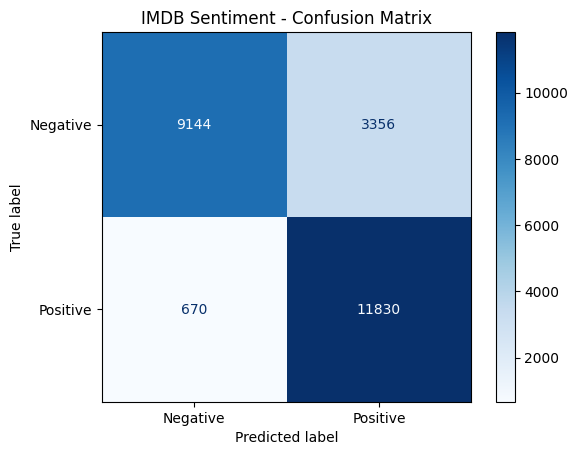

In [2]:
# Q2: IMDB sentiment classification with LSTM
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from tensorflow.keras.datasets import imdb
from tensorflow.keras.layers import LSTM, Dense, Embedding
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE, MAX_LEN = 10_000, 200

# 1. Load dataset (already tokenized: words -> integer ids)
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
print("Train:", len(x_train), "Test:", len(x_test))

# 2. Padding: make every review exactly 200 tokens
x_train = pad_sequences(x_train, maxlen=MAX_LEN)
x_test = pad_sequences(x_test, maxlen=MAX_LEN)

# 3. Build and train LSTM classifier
model = Sequential([
    Embedding(VOCAB_SIZE, 128),
    LSTM(64),
    Dense(1, activation="sigmoid"),   # probability review is positive
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LEN))
model.summary()
model.fit(x_train, y_train, batch_size=64, epochs=3, validation_split=0.2)

# 4. Evaluate
print("\nTest accuracy:", model.evaluate(x_test, y_test, verbose=0)[1])
y_pred = (model.predict(x_test) > 0.5).astype("int32").ravel()

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix:\n", cm)
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("IMDB Sentiment - Confusion Matrix")
plt.show()


3)Convolution with stride and padding



In [4]:
# Q3: Convolution with different stride and padding
import numpy as np
import tensorflow as tf

input_matrix = np.arange(1, 26, dtype=np.float32).reshape(5, 5)   # 1..25
kernel = np.array([[0, 1, 0],
                   [1, -4, 1],
                   [0, 1, 0]], dtype=np.float32)

print("Input:\n", input_matrix)
print("\nKernel:\n", kernel)

# TF shapes: input (batch, H, W, channels), kernel (H, W, in_ch, out_ch)
x = input_matrix.reshape(1, 5, 5, 1)
k = kernel.reshape(3, 3, 1, 1)

for stride, padding in [(1, "VALID"), (1, "SAME"), (2, "VALID"), (2, "SAME")]:
    out = tf.nn.conv2d(x, k, strides=[1, stride, stride, 1], padding=padding)
    print(f"\n{'='*45}\nStride = {stride}, Padding = '{padding}'  -> shape {out.shape[1:3]}")
    print(out.numpy().squeeze())

Input:
 [[ 1.  2.  3.  4.  5.]
 [ 6.  7.  8.  9. 10.]
 [11. 12. 13. 14. 15.]
 [16. 17. 18. 19. 20.]
 [21. 22. 23. 24. 25.]]

Kernel:
 [[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]

Stride = 1, Padding = 'VALID'  -> shape (3, 3)
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

Stride = 1, Padding = 'SAME'  -> shape (5, 5)
[[  4.   3.   2.   1.  -6.]
 [ -5.   0.   0.   0. -11.]
 [-10.   0.   0.   0. -16.]
 [-15.   0.   0.   0. -21.]
 [-46. -27. -28. -29. -56.]]

Stride = 2, Padding = 'VALID'  -> shape (2, 2)
[[0. 0.]
 [0. 0.]]

Stride = 2, Padding = 'SAME'  -> shape (3, 3)
[[  4.   2.  -6.]
 [-10.   0. -16.]
 [-46. -28. -56.]]


 4)Task 1: Sobel edge detection

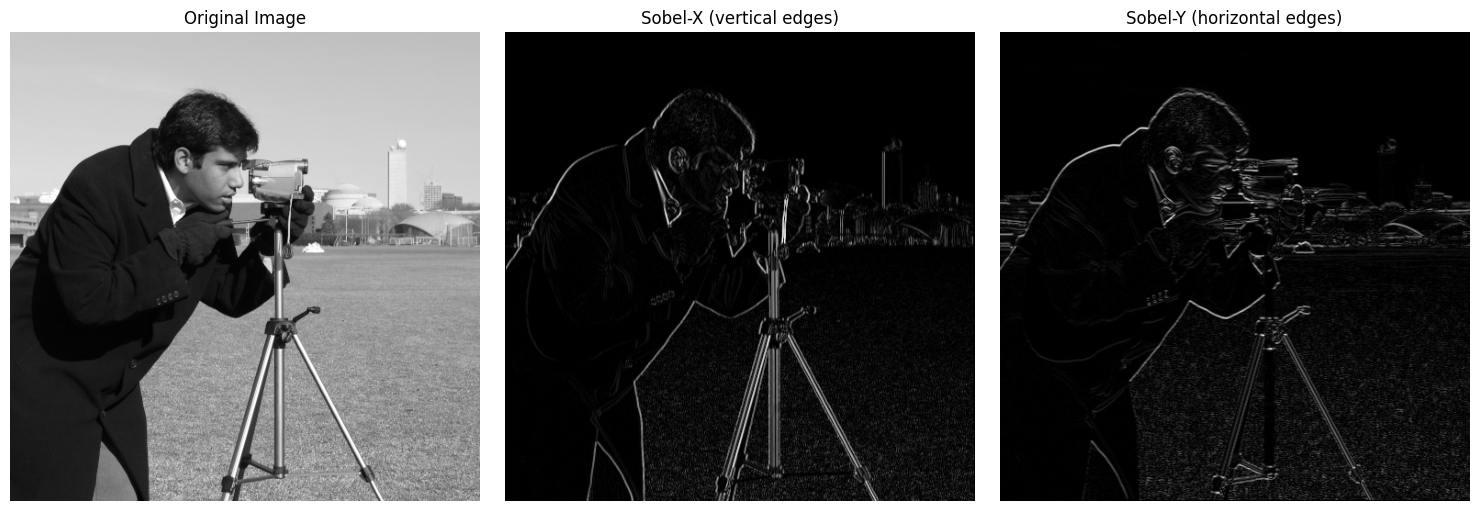

In [5]:
# Q4 Task 1: Sobel edge detection (uses a built-in sample image)
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

image = data.camera()   # 512x512 grayscale sample image

# Sobel kernels from the assignment
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)

# Convolve (64-bit float so negative gradients aren't clipped)
edges_x = cv2.filter2D(image, cv2.CV_64F, sobel_x)
edges_y = cv2.filter2D(image, cv2.CV_64F, sobel_y)

# Show absolute values for display
titles = ["Original Image", "Sobel-X (vertical edges)", "Sobel-Y (horizontal edges)"]
images = [image, np.abs(edges_x), np.abs(edges_y)]

plt.figure(figsize=(15, 5))
for i, (t, im) in enumerate(zip(titles, images), 1):
    plt.subplot(1, 3, i)
    plt.imshow(im, cmap="gray")
    plt.title(t)
    plt.axis("off")
plt.tight_layout()
plt.show()

Q4 Task 2: Max and average pooling

In [6]:
# Q4 Task 2: Max pooling and average pooling on a random 4x4 matrix
import numpy as np
from tensorflow.keras.layers import AveragePooling2D, MaxPooling2D

np.random.seed(42)   # reproducible
matrix = np.random.randint(0, 10, size=(4, 4)).astype(np.float32)
x = matrix.reshape(1, 4, 4, 1)   # (batch, H, W, channels)

max_pool = MaxPooling2D(pool_size=(2, 2), strides=2)(x)
avg_pool = AveragePooling2D(pool_size=(2, 2), strides=2)(x)

print("Original 4x4 matrix:\n", matrix)
print("\nMax-pooled (2x2):\n", max_pool.numpy().squeeze())
print("\nAverage-pooled (2x2):\n", avg_pool.numpy().squeeze())

Original 4x4 matrix:
 [[6. 3. 7. 4.]
 [6. 9. 2. 6.]
 [7. 4. 3. 7.]
 [7. 2. 5. 4.]]

Max-pooled (2x2):
 [[9. 7.]
 [7. 7.]]

Average-pooled (2x2):
 [[6.   4.75]
 [5.   4.75]]


Q5: AlexNet and ResNet-like model

In [8]:
# Q5: AlexNet + ResNet-like model
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (Activation, Add, Conv2D, Dense, Dropout,
                                     Flatten, MaxPooling2D)
from tensorflow.keras.models import Sequential

# ---------- Task 1: Simplified AlexNet ----------
alexnet = Sequential([
    Input(shape=(227, 227, 3)),
    Conv2D(96, (11, 11), strides=4, activation="relu"),
    MaxPooling2D(pool_size=(3, 3), strides=2),
    Conv2D(256, (5, 5), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(3, 3), strides=2),
    Conv2D(384, (3, 3), padding="same", activation="relu"),
    Conv2D(384, (3, 3), padding="same", activation="relu"),
    Conv2D(256, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(3, 3), strides=2),
    Flatten(),
    Dense(4096, activation="relu"),
    Dropout(0.5),
    Dense(4096, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax"),
], name="AlexNet")

print("AlexNet summary")
alexnet.summary()

# ---------- Task 2: Residual block + ResNet-like model ----------
def residual_block(input_tensor, filters=64):
    x = Conv2D(filters, (3, 3), padding="same", activation="relu")(input_tensor)
    x = Conv2D(filters, (3, 3), padding="same")(x)   # activation comes after the add
    x = Add()([x, input_tensor])                      # skip connection
    return Activation("relu")(x)

inputs = Input(shape=(64, 64, 3))
x = Conv2D(64, (7, 7), strides=2, padding="same", activation="relu")(inputs)
x = residual_block(x, 64)
x = residual_block(x, 64)
x = Flatten()(x)
x = Dense(128, activation="relu")(x)
outputs = Dense(10, activation="softmax")(x)
resnet = Model(inputs, outputs, name="ResNet_like")

print("\nResNet-like summary")
resnet.summary()

AlexNet summary


Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,322,314 (222.48 MB)

 Trainable params: 58,322,314 (222.48 MB)

...

Model: "ResNet_like"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 32,    │      9,472 │ input_layer_5[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_15[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_16[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 32, 32,    │          0 │ conv2d_17[0][0],  │
│                     │ 64)               │            │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add_2[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 32, 32,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_18[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 32, 32,    │          0 │ conv2d_19[0][0],  │
│                     │ 64)               │            │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ add_3[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 65536)     │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │  8,388,736 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 10)        │      1,290 │ dense_10[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,547,210 (32.61 MB)

 Trainable params: 8,547,210 (32.61 MB)

 Non-trainable params: 0 (0.00 B)